# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Song 2019's NSCLC malignant manifold is **non-branching**: the developmental signatures collapse
onto a **single dominant axis** — gastrulation/somitogenesis (Gast/pSom) high over the
developmental origin opposed to neural-crest (Crest) at a terminal end — rather than a hub
radiating to discrete subtypes with cross-repression. A PPT *tree* over this compact 1.1k-cell
cloud throws spurious forks; the geometry that matters is the signature geography: a single
**(Gast/pSom)→Crest** gradient with Gast and Crest strongly anti-correlated in space (smoothed
r ≈ −0.89) and Crest a single terminal tip. The correct topology is therefore a **principal
curve** (ElPiGraph, non-branching by construction) fit on the *joint* embedding — **not** a
re-embedding (re-embedding an anisotropic compartment fabricates folds).

**Scope decision (derived, not inherited).** The manifold is a **single Leiden lobe** with no
separable proliferative compartment (57% cycling but interspersed, one lobe at res=0.15), so the
Kürten / Lin cell-cycle-confound scoping question does not split the manifold. We still verify the
axis is developmental not proliferative — the developmental gene sets are essentially cell-cycle-
free, the Gast↔Crest anti-correlation survives within non-cycling cells alone, and pseudotime does
not track a cycling score — and keep the **whole manifold**. The curve is rooted at the Gast/pSom-
high tip and pseudotime flows to the neural-crest terminus. Deliverable: `manifold.h5ad`,
`manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
We keep all cells on their *original joint embedding coordinates* — no re-embedding. The three
embryonic signatures (Gastrulation / Somitogenesis / Neural-crest) are scored against the shared
**union** control pool and graph-smoothed to read geography rather than 10x per-cell dropout.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']
from numpy.linalg import svd
c = xy - xy.mean(0); u,s,vt = svd(c, full_matrices=False)
print(f'UMAP principal-axis ratio (major/minor singular value): {s[0]/s[1]:.2f}')

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('raw module means (honest readout):',
      adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

whole malignant manifold: 1144 cells on the joint embedding
UMAP principal-axis ratio (major/minor singular value): 1.34
Gast: 37/81 genes present
pSom: 49/98 genes present
Crest: 56/104 genes present
raw module means (honest readout): {'Gast': -0.0134, 'pSom': 0.08, 'Crest': -0.052}


### Scope decision — whole manifold (cell-cycle-free single body)
The manifold is one Leiden lobe, so there is no proliferative lobe to scope out. We still verify
the axis is developmental not proliferative: (i) the developmental gene sets are essentially
**cell-cycle-free** (overlap with the Regev–Tirosh S+G2M programme); (ii) the Gast↔Crest spatial
anti-correlation **survives within non-cycling cells alone**; (iii) pseudotime does not track a
cycling score (checked below once fit). Whole manifold kept (no scoping).

In [4]:
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
s_genes = set(('MCM5 PCNA TYMS FEN1 MCM2 MCM4 RRM1 UNG GINS2 MCM6 CDCA7 DTL PRIM1 UHRF1 HELLS RFC2 RPA2 '
    'NASP RAD51AP1 GMNN WDR76 SLBP CCNE2 UBR7 POLD3 MSH2 ATAD2 RAD51 RRM2 CDC45 CDC6 EXO1 TIPIN DSCC1 '
    'BLM CASP8AP2 USP1 CLSPN POLA1 CHAF1B BRIP1 E2F8').split())
g2m_genes = set(('HMGB2 CDK1 NUSAP1 UBE2C BIRC5 TPX2 TOP2A NDC80 CKS2 NUF2 CKS1B MKI67 TMPO CENPF TACC3 '
    'FAM64A SMC4 CCNB2 CKAP2L CKAP2 AURKB BUB1 KIF11 ANP32E TUBB4B GTSE1 KIF20B HJURP CDCA3 HN1 CDC20 TTK '
    'CDC25C KIF2C RANGAP1 NCAPD2 DLGAP5 CDCA2 CDCA8 ECT2 KIF23 HMMR AURKA PSRC1 ANLN LBR CKAP5 CENPE CTCF '
    'NEK2 G2E3 GAS2L3 CBX5 CENPA').split())
cc = s_genes | g2m_genes
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    ov = set(feat[src]) & cc
    print(f'  {lab}: {len(ov)}/{len(set(feat[src]))} genes overlap the cell-cycle programme')
noncyc = ~adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
r_all = np.corrcoef(adata.obs['Gast_sm'], adata.obs['Crest_sm'])[0,1]
r_nc  = np.corrcoef(adata.obs.loc[noncyc.values,'Gast_sm'], adata.obs.loc[noncyc.values,'Crest_sm'])[0,1]
print(f'  Gast<->Crest smoothed: all r={r_all:+.2f} | non-cycling only r={r_nc:+.2f} ({int(noncyc.sum())} cells)')
print('-> developmental axis is cell-cycle-free and survives without cycling cells; keep whole manifold (no scoping).')
sub = adata   # whole manifold is the trajectory object

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = -0.12
  Crest_sm vs Gast_sm: r = -0.89
  Crest_sm vs pSom_sm: r = -0.28
  Gast: 0/81 genes overlap the cell-cycle programme
  pSom: 2/98 genes overlap the cell-cycle programme
  Crest: 0/104 genes overlap the cell-cycle programme
  Gast<->Crest smoothed: all r=-0.89 | non-cycling only r=-0.87 (495 cells)
-> developmental axis is cell-cycle-free and survives without cycling cells; keep whole manifold (no scoping).


### Fit the principal curve (ElPiGraph)
`Nodes/epg_lambda/epg_mu` give a **fold-free** monotone backbone: a node self-approach ratio > 1
(minimum distance between graph-non-adjacent nodes, in units of median edge length) certifies the
curve does not fold back on itself. `epg_mu=100` is strong bending regularisation, keeping the arc
smooth. Fold-freeness and the 2-tip / 0-fork topology are stable across Nodes = 15/20/30.

In [5]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks

for Nn in [15, 20, 30]:
    a2 = sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(a2, Nodes=Nn, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa, tips, forks = fold_diag(a2)
    print(f'curve N={Nn}: {tips} tips, {forks} forks | self-approach {sa:.2f}')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'chosen curve N=20: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve N=15: 2 tips, 0 forks | self-approach 2.99
curve N=20: 2 tips, 0 forks | self-approach 2.93
curve N=30: 2 tips, 0 forks | self-approach 2.30
chosen curve N=20: 2 tips, 0 forks | fold self-approach ratio = 2.93 (>1 = fold-free)


### Derive the root (data-driven)
The root is the curve tip where Gast+pSom is highest and Crest lowest — the developmental origin.
Pseudotime then flows to the neural-crest terminus.

In [6]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')
tn = (t-t.min())/(t.max()-t.min())
for m,lab_ in [('Crest_sm','Neural-crest'),('pSom_sm','Somitogenesis'),('Gast_sm','Gastrulation')]:
    hi = sub.obs[m] >= sub.obs[m].quantile(0.9)
    print(f'{lab_}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')
g2m = pd.to_numeric(sub.obs['g2m_score'], errors='coerce').fillna(0).values
g1s = pd.to_numeric(sub.obs['g1s_score'], errors='coerce').fillna(0).values
cyc = np.maximum(g1s, g2m)
rho_c,_ = spearmanr(t, cyc); print(f'caveat: pseudotime vs cycling score rho = {rho_c:+.2f} '
      '(cell-cycle-free axis; not proliferation-driven)')

tip 0: Gast=-0.0221 pSom=+0.0750 Crest=-0.0427
tip 2: Gast=+0.0030 pSom=+0.0810 Crest=-0.0635
derived root = tip 2 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.724 p=2.1e-186
  pSom_sm: rho=-0.366 p=1.3e-37
  Crest_sm: rho=+0.740 p=1.3e-198
Neural-crest-high decile mean pseudotime = 0.84
Somitogenesis-high decile mean pseudotime = 0.41
Gastrulation-high decile mean pseudotime = 0.04
caveat: pseudotime vs cycling score rho = -0.19 (cell-cycle-free axis; not proliferation-driven)


### Milestones by developmental end (data-driven)
The two curve tips are the developmental **Origin** (Gast/pSom-high) and the neural-crest
**Terminus** (Crest-high); we label milestones by which end each is nearest, so the trajectory
ends read biologically on the manifold panel.

In [7]:
ms = sub.obs['milestones'].astype(str)
# map each milestone to Origin/Terminus by mean Crest along it (low=Origin, high=Terminus)
mmean = sub.obs.groupby(ms, observed=True)['Crest_sm'].mean().sort_values()
new = {}
for i,m in enumerate(mmean.index):
    new[m] = 'Origin' if i == 0 else ('Terminus' if i == len(mmean)-1 else f'Mid{i}')
scf.tl.rename_milestones(sub, new=new)
print('milestones ->', new)
print('mean pseudotime by milestone:',
      sub.obs.groupby('milestones', observed=True)['t'].mean().round(2).to_dict())

milestones -> {'2': 'Origin', '0': 'Terminus'}
mean pseudotime by milestone: {'Terminus': 5.83, 'Origin': 1.19}


### House orientation (re-used from 01, verified against pseudotime)
The house orientation — a single rigid rotation of the diagonal developmental axis to horizontal
— was derived **once in 01** (rotation angle from the manifold's axis of maximal variance; sign
from the developmental-module geography, Gast/pSom-high origin on the left) and stored as
`X_umap_lin`. Every UMAP deliverable across 01–04 re-uses these exact coordinates, so orientation
is consistent by construction (binding). Here we **verify** that layout now that pseudotime
exists: the correlation of the stored `X_umap_lin` x-axis with pseudotime must be strongly
positive (low pseudotime = developmental origin on the left).

In [8]:
t = sub.obs['t'].values
r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])   # re-used from 01, not re-derived
c = sub.obsm['X_umap'] - sub.obsm['X_umap'].mean(0)
dirv = np.array([np.cov(c[:,0], t)[0,1], np.cov(c[:,1], t)[0,1]])
_, _, vt = np.linalg.svd(c, full_matrices=False)
dang = abs(np.degrees(np.arctan2(dirv[1],dirv[0]) - np.arctan2(vt[0,1],vt[0,0]))) % 180
dang = min(dang, 180-dang)
if r < 0:      # ensure origin on the left for this dataset's layout
    sub.obsm['X_umap_lin'][:,0] = -sub.obsm['X_umap_lin'][:,0]
    r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
assert r > 0.5, f'stored orientation not pseudotime-consistent (corr={r:.2f})'
print(f'house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = {r:+.2f}')
print(f'variance-axis vs pseudotime-axis disagreement = {dang:.1f}deg (small -> equivalent orientation)')

house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = +0.97
variance-axis vs pseudotime-axis disagreement = 5.0deg (small -> equivalent orientation)


### Save manifold + trajectory figure (deliverable)

saved manifold.h5ad + manifold.pdf


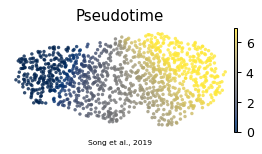

In [9]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Song et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')